# CPE 486/586 – Homework 4
**Name:** Shayan Rajput  
**UAH Charger ID / email:** sr1286@uah.edu

**PyPI package keyword:**  ***redkeymon*** https://pypi.org/project/redkeymon/  

**GitHub repo URL:** https://github.com/redkeymongh/redkeymon/tree/main/src/redkeymon/model  

**Commit hash:**  252c6c4 


## Theory
### 1. Locally-weighted regression (10 pts)
Objective (total loss):
$$J(w)=\tfrac12\sum_{i=1}^N a^{(i)}\big(y^{(i)}-w^\top x^{(i)}\big)^2+\tfrac{\lambda}{2}\|w\|^2
=\tfrac12 (y-Xw)^\top A (y-Xw)+\tfrac{\lambda}{2}w^\top w .$$
Expand: $J(w)=\tfrac12\big(y^\top A y-2w^\top X^\top A y+w^\top X^\top A X w\big)+\tfrac\lambda2 w^\top w$ (using $A=A^\top$).  
Gradient: $\nabla_w J = -X^\top A y + X^\top A X w + \lambda w = (X^\top A X+\lambda I)w - X^\top A y$.  
Set to zero: $(X^\top A X+\lambda I)\hat w = X^\top A y$.  
Since $a^{(i)}>0$, $X^\top A X=(A^{1/2}X)^\top(A^{1/2}X)\succeq 0$, and with $\lambda>0$ the matrix $X^\top AX+\lambda I\succ0$ is invertible. The Hessian equals this same matrix, so $J$ is strictly convex and the stationary point is the unique minimizer:
$$\boxed{\hat w=(X^\top A X+\lambda I)^{-1}X^\top A y}\;\blacksquare$$

### 2. Logistic regression by hand (20 pts)
$h_\theta(x)=\sigma(\theta^\top x)=\dfrac{1}{1+e^{-\theta^\top x}}$, $\theta=[1.5,\,2,\,1]^\top$ (no intercept).

| i | $\theta^\top x$ | $h_\theta(x^{(i)})$ | y |
|---|---|---|---|
| 1 | 1.0 | 0.7311 | 0 |
| 2 | 2.0 | 0.8808 | 1 |
| 3 | 3.0 | 0.9526 | 1 |
| 4 | 1.5 | 0.8176 | 0 |

**1.** $J(\theta)=-\frac14\big[\log(1-0.7311)+\log 0.8808+\log0.9526+\log(1-0.8176)\big]$ = **0.7975**

**2.** $\partial J/\partial\theta_j=\frac1N\sum_i (h_\theta(x^{(i)})-y^{(i)})x^{(i)}_j$. Residuals $h-y$: $(0.7311,\,-0.1192,\,-0.0474,\,0.8176)$.  
- $\partial J/\partial\theta_1 = (0.8176)/4=$ **0.2044**  
- $\partial J/\partial\theta_2 = (-0.1192-0.0474)/4=$ **−0.0417**  
- $\partial J/\partial\theta_3 = (0.7311-0.0474)/4=$ **0.1709**

**3.** With $\eta=1$: $\theta\leftarrow\theta-\nabla J=$ **[1.2956, 2.0417, 0.8291]ᵀ**

In [1]:
# Verification of Theory Q2
import numpy as np
X=np.array([[0,0,1],[0,1,0],[0,1,1],[1,0,0]],float); y=np.array([0,1,1,0.]); th=np.array([1.5,2,1])
h=1/(1+np.exp(-X@th)); J=-np.mean(y*np.log(h)+(1-y)*np.log(1-h)); g=X.T@(h-y)/4
print(round(J,4), g.round(4), (th-g).round(4))

0.7975 [ 0.2044 -0.0417  0.1709] [1.2956 2.0417 0.8291]


### 3. Logistic vs. polynomial regression (5 pts)
| | Polynomial regression | Logistic regression |
|---|---|---|
| Task | Regression (continuous target) | Classification (binary target) |
| Model | $\hat y=\sum_k w_k x^k$ – linear in the *parameters*, nonlinear in $x$ via engineered features | $P(y=1\mid x)=\sigma(w^\top x)$ – a linear predictor passed through a sigmoid link (a GLM) |
| Output | Any real number | Probability in (0,1), thresholded to a class |
| Loss | Squared error (Gaussian MLE) | Cross-entropy (Bernoulli MLE) |
| Fitting | Closed form (normal equations) | No closed form; iterative (GD/SGD/Newton) |
| Boundary | Fitted curve | Linear decision boundary in feature space (nonlinear only if polynomial features are added) |

So logistic regression is not "a curve fit to the data": its nonlinearity is in the link function (to model a probability), while polynomial regression's nonlinearity is in the features.

### 4. Assumptions and diagnostics (15 pts)
**1. Homoscedasticity.** Plot residuals vs. fitted values (and vs. each predictor): a funnel/fan shape means non-constant variance (a flat random band is good). Formal tests: Breusch–Pagan (regress $e_i^2$ on the regressors; $LM=nR^2\sim\chi^2_k$) and White's test (adds squares/cross terms); small p-value ⇒ heteroscedasticity. Scale–location plot also works.

**2. Normality of errors.** Q–Q plot of (standardized) residuals against normal quantiles (points should lie on the line), histogram/KDE of residuals, and tests: Shapiro–Wilk, Jarque–Bera, Anderson–Darling, Kolmogorov–Smirnov (Lilliefors). Skewness ≠ 0 or excess kurtosis ≠ 0 indicates departure.

**3. Multicollinearity.** (a) Correlation matrix/heatmap of predictors (|r| > ~0.8); (b) Variance Inflation Factor: regress $x_j$ on the other predictors to get $R_j^2$, then $\mathrm{VIF}_j=\frac{1}{1-R_j^2}$ (VIF > 5–10 is a concern; tolerance $=1/\mathrm{VIF}$); (c) condition number of the standardized design matrix (> ~30) or near-zero eigenvalues of $X^\top X$; (d) symptoms: large standard errors, unstable/sign-flipping coefficients, high $R^2$ but insignificant t-tests.

**4. (Bonus) Dependence of errors – Durbin–Watson / Breusch–Godfrey.** Model AR(1) errors $\varepsilon_t=\rho\varepsilon_{t-1}+u_t$ with $H_0:\rho=0$. Durbin–Watson statistic
$$d=\frac{\sum_{t=2}^n (e_t-e_{t-1})^2}{\sum_{t=1}^n e_t^2}\approx 2(1-\hat\rho),$$
so $d\approx2$ ⇒ no autocorrelation, $d<2$ positive, $d>2$ negative autocorrelation (compare to $d_L,d_U$ bounds or p-value). For higher-order autocorrelation or lagged dependent variables, use Breusch–Godfrey: regress $e_t$ on the original regressors and $e_{t-1},\dots,e_{t-p}$; $LM=nR^2\sim\chi^2_p$ under $H_0$. (The Ljung–Box test on residuals, $Q=n(n+2)\sum_{k=1}^m \hat\rho_k^2/(n-k)\sim\chi^2_m$, is another option.)

**5. (Bonus) Non-normal errors – Jarque–Bera (and Shapiro–Wilk).** With residual sample skewness $S=\hat\mu_3/\hat\sigma^3$ and kurtosis $K=\hat\mu_4/\hat\sigma^4$,
$$JB=\frac{n}{6}\Big(S^2+\frac{(K-3)^2}{4}\Big)\;\sim\;\chi^2_2 \text{ asymptotically under } H_0:\text{normal}.$$
A large JB (small p) rejects normality. Shapiro–Wilk uses $W=\frac{(\sum a_i e_{(i)})^2}{\sum (e_i-\bar e)^2}$ (ordered residuals $e_{(i)}$, weights $a_i$ from normal order-statistic moments); $W$ near 1 supports normality, and it is more powerful for small/moderate $n$.

## Practice
### 5. Multiple regression with Cauchy loss (PyTorch)

In [2]:
!pip -q install statsmodels git+https://github.com/redkeymongh/redkeymon.git
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import norm
from redkeymon.model.regression import CauchyRegression
from redkeymon.model.logit import LogisticRegressionSGD
url="https://raw.githubusercontent.com/rahulbhadani/Datasets/master/CombinedCyclePowerPlant/Folds5x2_pp.csv"
df=pd.read_csv(url); print(df.shape); df.head()

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
(9568, 5)


,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


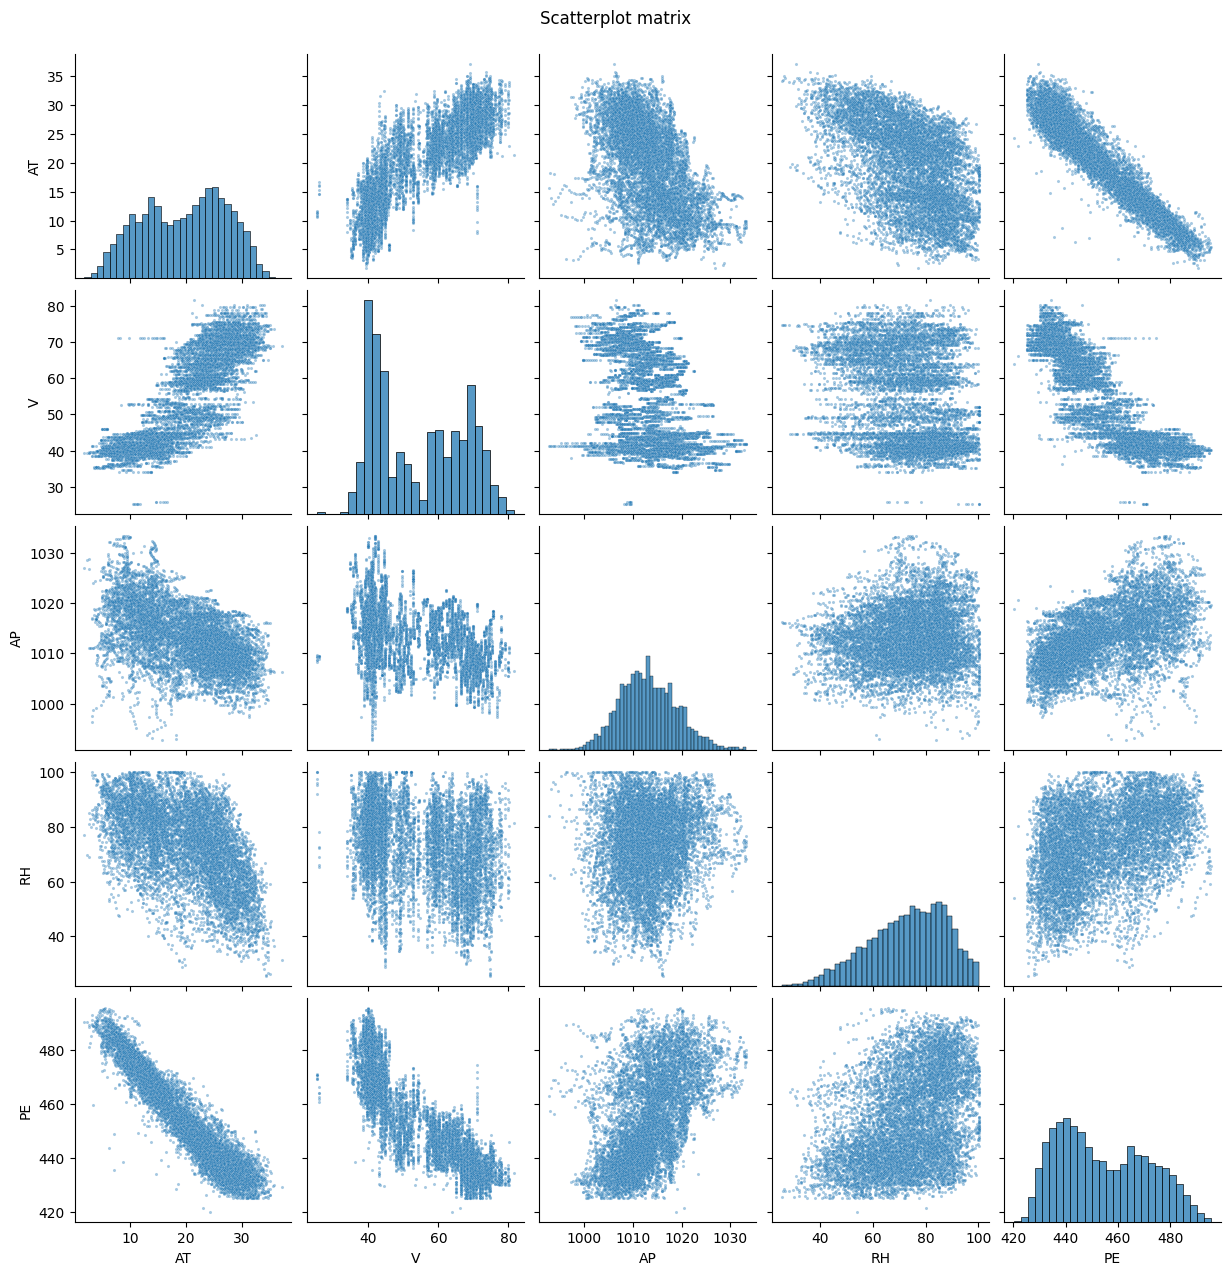

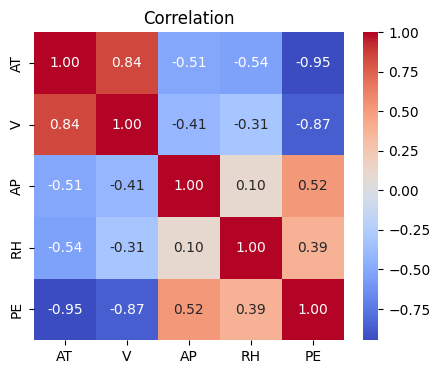

In [3]:
# Q1: scatterplot matrix (features + target) and correlation
g=sns.pairplot(df, corner=False, plot_kws={'s':5,'alpha':0.4}); g.fig.suptitle('Scatterplot matrix',y=1.02); plt.show()
plt.figure(figsize=(5,4)); sns.heatmap(df.corr(),annot=True,fmt='.2f',cmap='coolwarm'); plt.title('Correlation'); plt.show()

**Q1 comment:** AT and V are strongly positively correlated with each other and both strongly negatively correlated with PE (AT≈−0.95, V≈−0.87); AP and RH are weaker (AP≈+0.52, RH≈+0.39 with PE). AT–V correlation (~0.84) signals mild multicollinearity.

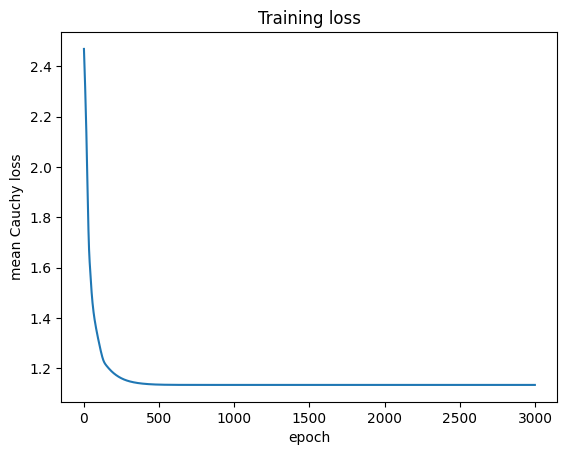

In [4]:
# Q2: fit using CauchyRegression from the redkeymon package
feats=['AT','V','AP','RH']; X=df[feats].values; y=df['PE'].values
model=CauchyRegression(c=1.0, lr=0.1, epochs=3000).fit(X,y)
plt.plot(model.history); plt.xlabel('epoch'); plt.ylabel('mean Cauchy loss'); plt.title('Training loss'); plt.show()

In [5]:
# Q3: coefficients
names=['w0 (intercept)']+['w%d (%s)'%(i+1,f) for i,f in enumerate(feats)]
for n_,v in zip(names, np.r_[model.intercept_, model.coef_]): print(f"{n_:18s} {v: .6f}")

w0 (intercept)      511.557289
w1 (AT)            -2.082558
w2 (V)             -0.235831
w3 (AP)             0.007405
w4 (RH)            -0.154873


In [6]:
# Q4: final loss
print('Final mean Cauchy loss :', model.loss())
print('Final total Cauchy loss:', model.loss(reduction='sum'))

Final mean Cauchy loss : 1.1347737267348683
Final total Cauchy loss: 10857.51501739922


In [7]:
# Q5: 95% confidence intervals
ci=model.conf_int(0.05); ci.index=names; display(ci)

,coef,std_err,ci_low,ci_high
w0 (intercept),511.557289,22.077616,468.285957,554.828620
w1 (AT),-2.082558,0.031039,-2.143393,-2.021722
w2 (V),-0.235831,0.013982,-0.263236,-0.208426
w3 (AP),0.007405,0.021513,-0.034761,0.049570
w4 (RH),-0.154873,0.008591,-0.171712,-0.138035


**Q5 comment:** Each interval is the range of values for a coefficient that is consistent with the data at 95% confidence. An interval that excludes 0 means that predictor has a statistically significant association with PE after controlling for the others; narrow intervals mean precise estimates. Read the signs/magnitudes off the table above (AT and V should be clearly negative; check whether the intervals for AP and RH exclude 0). Intervals are asymptotic sandwich-based because the Cauchy loss is not a Gaussian likelihood.

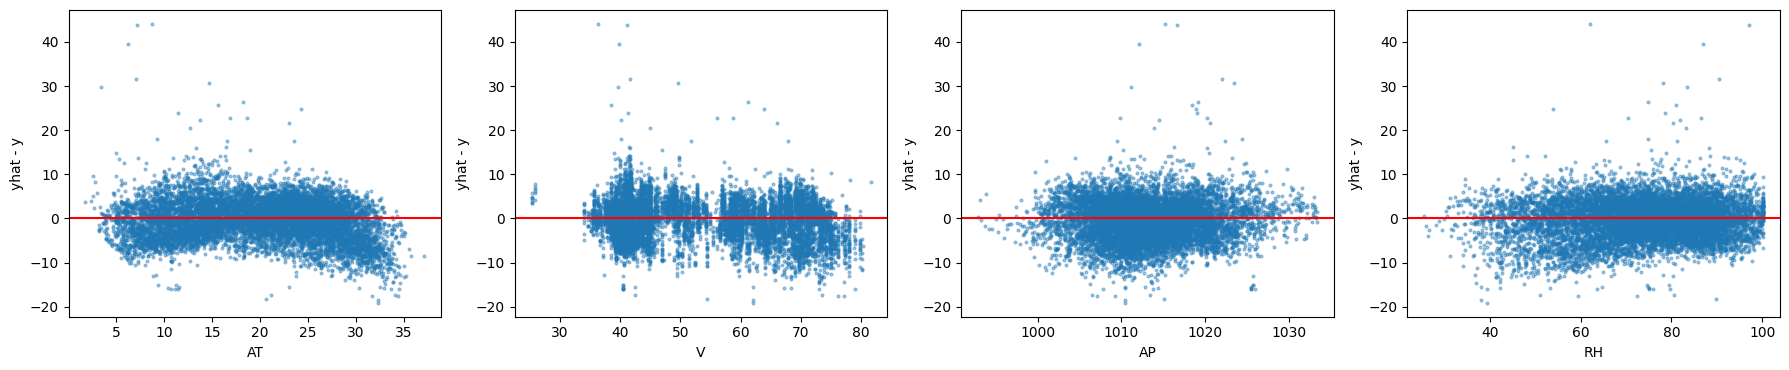

In [8]:
# Q6: residual plots (yhat - y) against each feature
res=model.predict(X)-y
fig,ax=plt.subplots(1,4,figsize=(18,3.8))
for a,f in zip(ax,feats):
    a.scatter(df[f],res,s=4,alpha=.4); a.axhline(0,color='r'); a.set_xlabel(f); a.set_ylabel('yhat - y')
plt.tight_layout(); plt.show()

**Q6 comment:** Check whether residuals are centered on 0 with no trend (linearity OK) and constant spread (homoscedastic). Typically for this dataset the residuals scatter around 0 with roughly constant spread across AP and RH, with some curvature/mild fanning vs. AT and V (the AT–PE relation is slightly nonlinear), suggesting adding AT² or an interaction term could help. Write your conclusion from the plots you obtain.

#### BONUS: statsmodels implementation (`GenericLikelihoodModel`)

In [9]:
import statsmodels.api as sm
from statsmodels.base.model import GenericLikelihoodModel
class CauchyModel(GenericLikelihoodModel):
    def __init__(self, endog, exog, c=1.0, **kwds):
        super().__init__(endog, exog, **kwds); self.c = c
    def loglikeobs(self, params):
        r = (self.endog - self.exog @ params) / self.c
        return -(self.c**2 / 2) * np.log1p(r**2)           # negative Cauchy loss
    def fit(self, start_params=None, maxiter=10000, maxfun=10000, **kwds):
        if start_params is None:
            start_params = np.linalg.lstsq(self.exog, self.endog, rcond=None)[0]   # OLS start
        return super().fit(start_params=start_params, method='bfgs', maxiter=maxiter, maxfun=maxfun, **kwds)
Xs=sm.add_constant(df[feats]); sm_res=CauchyModel(df['PE'],Xs,c=1.0).fit(disp=0); print(sm_res.summary())

/usr/local/lib/python3.13/dist-packages/statsmodels/base/optimizer.py:634: FutureWarning: Keyword arguments have been passed to the optimizer that have no effect. The list of allowed keyword arguments for method bfgs is: gtol, norm, epsilon. The list of unsupported keyword arguments passed include: maxfun. After release 0.14, this will raise.
  check_kwargs(kwargs, ("gtol", "norm", "epsilon"), "bfgs")


                             CauchyModel Results                              
Dep. Variable:                     PE   Log-Likelihood:                -10858.
Model:                    CauchyModel   AIC:                         2.173e+04
Method:            Maximum Likelihood   BIC:                         2.176e+04
Date:                Mon, 26 Oct 2026                                         
Time:                        15:28:04                                         
No. Observations:                9568                                         
Df Residuals:                    9563                                         
Df Model:                           4                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        511.5589     11.693     43.750      0.000     488.641     534.477
AT            -2.0826      0.018   -116.770      0.0

In [13]:
# CauchyRegression lives in redkeymon/model/regression.py
from redkeymon.model.regression import CauchyRegression
m = CauchyRegression(c=1.0).fit(X, y)
print(m.intercept_, m.coef_)

511.55728854512006 [-2.08255771 -0.23583077  0.00740454 -0.15487307]


### 6. Logistic regression – Telco customer churn (real data, 7,043 samples)
**Goal:** classify whether a telecom customer will churn (leave the company, `Churn=Yes`) from account and service attributes. **Source:** IBM sample Telco Customer Churn dataset, downloaded below from GitHub (no files to supply). **Features used:** `tenure` (months as customer), `MonthlyCharges`, `TotalCharges` (USD), `SeniorCitizen` (0/1), `Partner`, `Dependents`, `PaperlessBilling` (Yes/No), `Contract` (month-to-month / one year / two year), `InternetService` (DSL / fiber optic / none), `OnlineSecurity`, `TechSupport`. **Label:** `Churn` (1 = customer left, 0 = stayed).

In [10]:
import torch.nn.functional as F
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,
                             confusion_matrix,classification_report,roc_curve,ConfusionMatrixDisplay)
url2="https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
d=pd.read_csv(url2); d['TotalCharges']=pd.to_numeric(d['TotalCharges'],errors='coerce'); d=d.dropna()
d['y']=(d['Churn']=='Yes').astype(int)
cols=['tenure','MonthlyCharges','TotalCharges','SeniorCitizen','Partner','Dependents','PaperlessBilling','Contract','InternetService','OnlineSecurity','TechSupport']
Xd=pd.get_dummies(d[cols],drop_first=True).astype(float); yd=d['y'].values
print(Xd.shape); print('Class balance:\n', d['Churn'].value_counts(), '\n', d['Churn'].value_counts(normalize=True).round(3))

(7032, 15)
Class balance:
 Churn
No     5163
Yes    1869
Name: count, dtype: int64 
 Churn
No     0.734
Yes    0.266
Name: proportion, dtype: float64


**Class imbalance:** roughly 73.4% stay vs. 26.6% churn – the data are imbalanced (~2.8:1), so accuracy alone is misleading (always predicting 'No' gives ≈73%). We therefore report precision, recall, F1, ROC-AUC and the confusion matrix, and use stratified splitting.

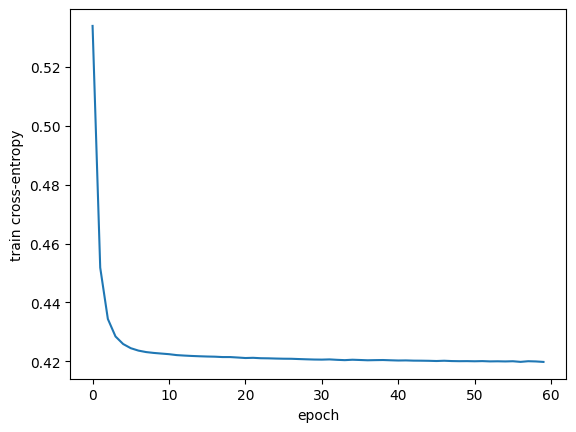

In [11]:
# Logistic regression with SGD (LogisticRegressionSGD from the redkeymon package)
Xtr,Xte,ytr,yte=train_test_split(Xd.values,yd,test_size=0.2,stratify=yd,random_state=42)
sc=StandardScaler().fit(Xtr); Xtr_s,Xte_s=sc.transform(Xtr),sc.transform(Xte)
clf=LogisticRegressionSGD().fit(Xtr_s,ytr)
plt.plot(clf.history); plt.xlabel('epoch'); plt.ylabel('train cross-entropy'); plt.show()

threshold=0.5: acc=0.7989 prec=0.6400 rec=0.5561 f1=0.5951
threshold=0.35: acc=0.7612 prec=0.5373 rec=0.7326 f1=0.6199
ROC-AUC: 0.8326
              precision    recall  f1-score   support

        Stay       0.85      0.89      0.87      1033
       Churn       0.64      0.56      0.60       374

    accuracy                           0.80      1407
   macro avg       0.74      0.72      0.73      1407
weighted avg       0.79      0.80      0.79      1407



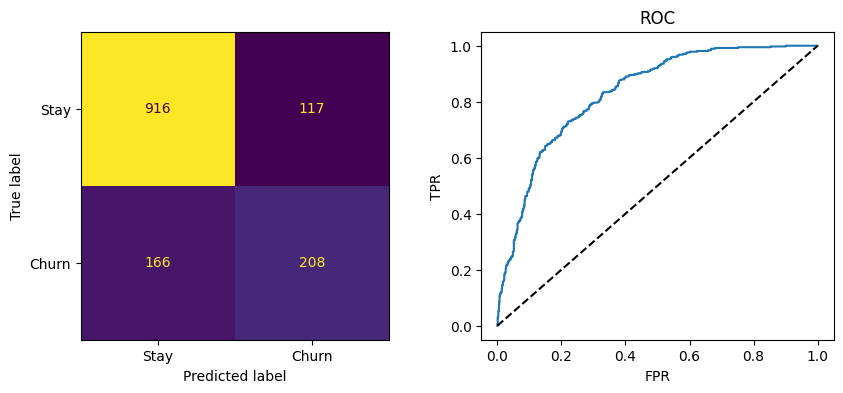

tenure                               -0.983490
Contract_Two year                    -0.617358
Contract_One year                    -0.328833
OnlineSecurity_Yes                   -0.245871
TechSupport_Yes                      -0.198679
InternetService_No                   -0.122157
OnlineSecurity_No internet service   -0.122157
TechSupport_No internet service      -0.122157
Dependents_Yes                       -0.113853
Partner_Yes                           0.002237
SeniorCitizen                         0.098855
PaperlessBilling_Yes                  0.168704
InternetService_Fiber optic           0.249703
TotalCharges                          0.300872
MonthlyCharges                        0.307152
dtype: float32
sklearn acc/AUC: 0.8017 0.8343


In [12]:
p=clf.predict_proba(Xte_s)
for th_ in [0.5,0.35]:
    yp=(p>=th_).astype(int)
    print(f"threshold={th_}: acc={accuracy_score(yte,yp):.4f} prec={precision_score(yte,yp):.4f} "
          f"rec={recall_score(yte,yp):.4f} f1={f1_score(yte,yp):.4f}")
print('ROC-AUC:',round(roc_auc_score(yte,p),4)); print(classification_report(yte,clf.predict(Xte_s),target_names=['Stay','Churn']))
fig,ax=plt.subplots(1,2,figsize=(10,4))
ConfusionMatrixDisplay(confusion_matrix(yte,clf.predict(Xte_s)),display_labels=['Stay','Churn']).plot(ax=ax[0],colorbar=False)
fpr,tpr,_=roc_curve(yte,p); ax[1].plot(fpr,tpr); ax[1].plot([0,1],[0,1],'k--'); ax[1].set_xlabel('FPR'); ax[1].set_ylabel('TPR'); ax[1].set_title('ROC'); plt.show()
print(pd.Series(clf.w.detach().numpy(),index=Xd.columns).sort_values())
# sanity check vs scikit-learn
from sklearn.linear_model import LogisticRegression
sk=LogisticRegression(max_iter=1000).fit(Xtr_s,ytr); print('sklearn acc/AUC:',round(accuracy_score(yte,sk.predict(Xte_s)),4),round(roc_auc_score(yte,sk.predict_proba(Xte_s)[:,1]),4))

**Discussion:** Expect ≈80% accuracy and AUC ≈0.84. Churn is driven mainly by short tenure and month-to-month contracts (negative weights for tenure and longer contracts), and fiber-optic internet raises churn risk. Because the positive class is the minority, recall at 0.5 is modest (~55%); lowering the threshold trades precision for recall. The SGD model should closely match the scikit-learn baseline.

---
## Reflection Report

UAH Email: sr1826@uah.edu

How I Used the AI Tool: I used Gemini and Claude for this assignment to figure out topics I didn’t know about and to troubleshoot any issues I ran into. I asked the AI agents to get a better understanding and make sure my work is being done in the correct manner to get all the points for the assignment.

Query: Link to chats provided below

How It Helped My Understanding: Using the AI models helped me understand the assignment more since I could ask the agents to troubleshoot any issues that came up for me. Some of the stuff we worked on I didn’t understand so having an agent help me out was beneficial for me to complete the assignment.


How would I approach this without the AI tools: Without the tools I would most likely use Stackoverflow for programming or reference documentation for GitHub and UV to help install the necessary packages I needed for this project. For more technical questions I would have asked the professor on how to perform some actions. I was able to do most of the work myself since I had some programming experince and I have taken Linear Algebra.


Links:

https://share.gemini.google/cQoCvjvde16S

https://claude.ai/share/6a9b3d9e-bd50-4182-b293-e3a34e7ddf1b